## Final Project - SEIS-632-02
### Group 4 Members
#### Mark Anson
#### Matt Becker
#### Matt Carnes
#### Faiyak Zaman
#### Liz Zupfer

## Premise:
### I am a real estate investor and would like to invest 12M dollars in the real estate market. I am particularly interested in single family homes or rental apartments unless you recommend other types of real estate which may return maximum profits. My interest is to buy properties, do the upgrades and then rent the properties, however I am also interested in blooming markets where if needed, I can sell the properties quickly. What part of the country should I invest in to receive maximum gains.

### To begin with we create the framework that all of our visualizations will be based on

Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pingouin as pg
import scipy.stats as sp
from sklearn.linear_model import LinearRegression

Datasets we are using, we assigned them variables to allow easier collaboration and make sure we are all using the same files

In [4]:
homeValues = "Metro_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
homeValuesForecast = "Metro_zhvf_growth_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
rentalsIndex = "Metro_zori_uc_sfrcondomfr_sm_month.csv"
rentalSingle = "National_zorf_growth_uc_sfr_sm_month.csv"
rentalMulti = "National_zorf_growth_uc_mfr_sm_month.csv"
forSaleList = "Metro_invt_fs_uc_sfrcondo_sm_month.csv"
salesCount = "Metro_sales_count_now_uc_sfrcondo_month.csv"
salesPrice = "Metro_median_sale_price_now_uc_sfrcondo_month.csv"
marketDays = "Metro_med_doz_pending_uc_sfrcondo_sm_month.csv"
marketHeatIndex = "Metro_market_temp_index_uc_sfrcondo_month.csv"
downPayment = "Metro_total_monthly_payment_downpayment_0.20_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
mortgagePayment = "Metro_mortgage_payment_downpayment_0.20_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"

Here we create the original versions of each DataFrame. We end up creating multiple versions of some of them throughout the project for ease of use and collaboration

In [8]:
rent_df = pd.read_csv(rentalsIndex)
sale_count_df = pd.read_csv(salesCount)
heat_index_df = pd.read_csv(marketHeatIndex)
inventory_df = pd.read_csv(forSaleList)
market_growth = pd.read_csv(homeValuesForecast)
home_value_df = pd.read_csv(homeValues)
price_df = pd.read_csv(salesPrice)

FileNotFoundError: [Errno 2] No such file or directory: 'Metro_sales_count_now_uc_sfrcondo_month.csv'

First we start by transforming a given dataset, we repeat this process many times throughout to similar effect.

In [227]:
rent_df_transformed = (rent_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .interpolate(axis=0, limit_direction='forward') # Use linear interpolation to inpute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='RentalPrice') # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .sort_values(by=['Date'], ascending=False)
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'") # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'RentalPrice': 'mean'}) # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['RentalPrice'], ascending=False)
 .reset_index()
)

C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\3865005072.py:3: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward') # Use linear interpolation to inpute missing values


Next we start with a basic visualization for the dataset in order to get a more clear idea in our minds of what the data looks like

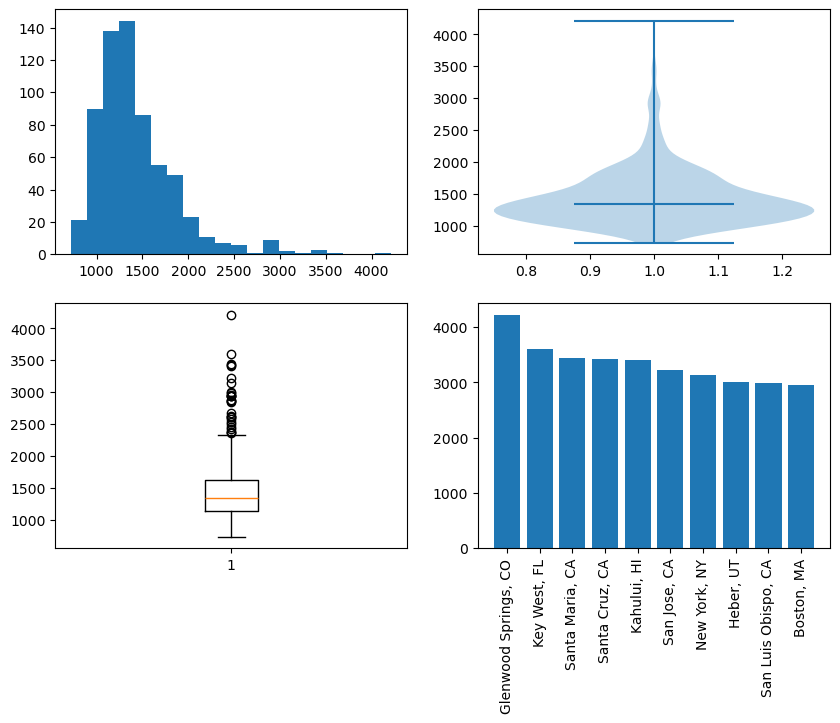

In [228]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.RentalPrice, bins=20)
    ax[0,1].violinplot(df.RentalPrice, showmedians=True)
    ax[1,0].boxplot(df.RentalPrice)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.RentalPrice.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(rent_df_transformed
 .pipe(graph)
)

Determine how many Regions in each state have above 75th percentile Rental prices, this is what we care about and want to bring forward

In [229]:
rent_df_cleaned = (rent_df_transformed
 .query("RentalPrice > 1569")  # filter dataset to only RentalPrices above 75th percentile
 .groupby(['StateName'])
 .agg({'RegionName': 'count'}) # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'RegionName': 'TopRentalRegions'})
)
rent_df_cleaned

,TopRentalRegions
StateName,
CA,26
FL,20
CO,10
NC,9
WA,9
OR,8
NY,7
VA,7
GA,7


We repeat the process with each of the datasets

In [230]:
sale_count_df_transformed = (sale_count_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US          
 .interpolate(axis=0, limit_direction='forward')  # Use linear interpolation to inpute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='SaleCount')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .sort_values(by=['Date'], ascending=False)
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")  # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'SaleCount': 'mean'})  # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['SaleCount'], ascending=False)
 .reset_index()
)
sale_count_df_transformed

C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\2894884701.py:3: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward')  # Use linear interpolation to inpute missing values


,StateName,RegionName,SaleCount
0,NY,"New York, NY",13335.783784
1,IL,"Chicago, IL",9041.648649
2,FL,"Miami, FL",8118.675676
3,GA,"Atlanta, GA",7634.162162
4,CA,"Los Angeles, CA",6455.216216
...,...,...,...
88,TX,"El Paso, TX",552.729730
89,NY,"Syracuse, NY",495.810811
90,CA,"Stockton, CA",492.540541
91,CO,"Fort Collins, CO",413.567568


Graphs for Sale Count

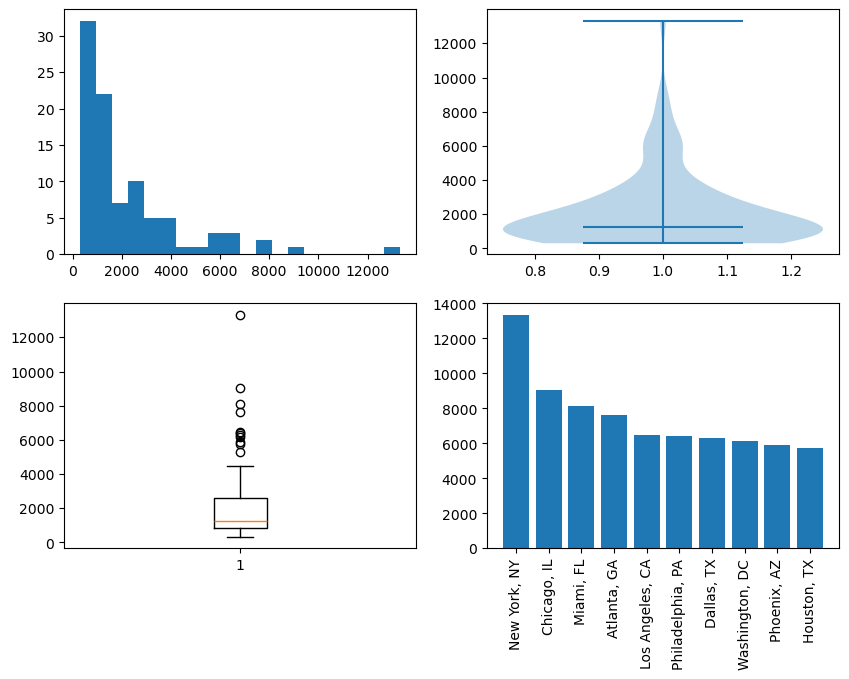

In [231]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.SaleCount, bins=20)
    ax[0,1].violinplot(df.SaleCount, showmedians=True)
    ax[1,0].boxplot(df.SaleCount)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.SaleCount.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(sale_count_df_transformed
 .pipe(graph)
)

Determine how many Regions in each state have above 75th percentile sale count

In [232]:
sale_count_df_cleaned = (sale_count_df_transformed
 .query("SaleCount > 2234")  # filter dataset to only SalesCount above 75th percentile
 .groupby(['StateName'])
 .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'RegionName': 'TopSalesRegions'})
)
sale_count_df_cleaned

,TopSalesRegions
StateName,
FL,4
CA,4
MO,2
VA,2
TX,2
PA,2
NC,1
TN,1
OR,1


Transform dataset

In [233]:
heat_index_df_transformed = (heat_index_df
 .dropna(subset=['StateName'])
 .interpolate(axis=0, limit_direction='forward')
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='IndexScore')
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")
 .groupby(['StateName', 'RegionName'])
 .agg({'IndexScore': 'mean'})
 .sort_values(by=['IndexScore'], ascending=False)
 .reset_index()
)
heat_index_df_transformed

C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\1595909338.py:3: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward')


,StateName,RegionName,IndexScore
0,NY,"Rochester, NY",152.540541
1,NY,"Buffalo, NY",100.621622
2,NY,"Syracuse, NY",99.648649
3,CA,"San Jose, CA",99.135135
4,CA,"San Francisco, CA",97.270270
...,...,...,...
922,OR,"Brookings, OR",30.135135
923,FL,"Palatka, FL",29.445946
924,FL,"Okeechobee, FL",26.500000
925,TN,"McMinnville, TN",22.121622


Graphs for Heat Index

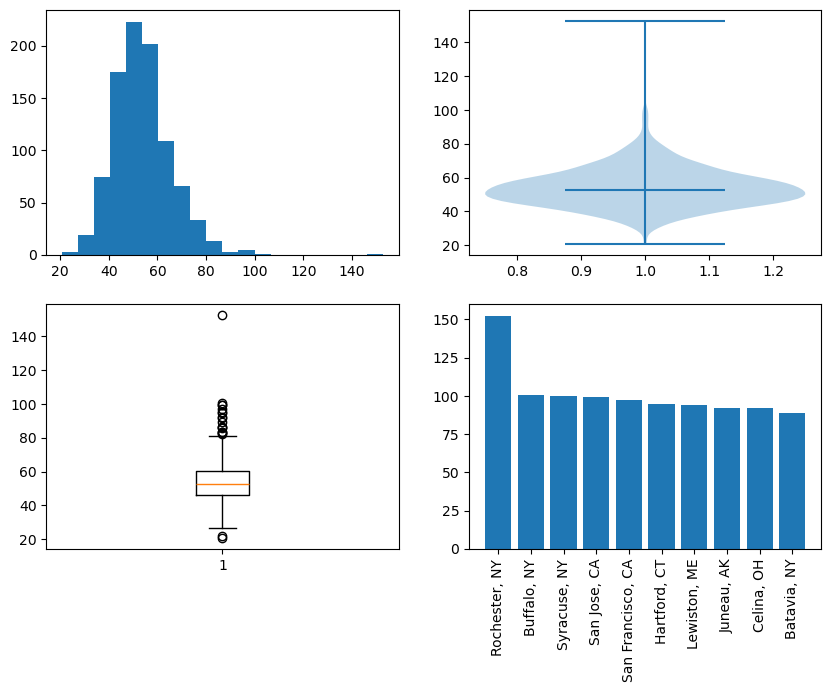

In [234]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.IndexScore, bins=20)
    ax[0,1].violinplot(df.IndexScore, showmedians=True)
    ax[1,0].boxplot(df.IndexScore)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.IndexScore.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(heat_index_df_transformed
 .pipe(graph)
)

Determine how many Regions in each state have above 75th percentile in heat index

In [235]:
heat_index_df_cleaned = (heat_index_df_transformed
 .query("IndexScore > 59") # filter dataset to only SalesCount above 75th percentile
 .groupby(['StateName'])
 .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'RegionName': 'TopMarketRegions'})
)
heat_index_df_cleaned

,TopMarketRegions
StateName,
CA,23
NY,19
OH,19
PA,18
IL,17
MN,16
MI,16
VA,12
WI,12


In [236]:
inventory_df_transformed = (inventory_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .interpolate(axis=0, limit_direction='forward')  # Use linear interpolation to impute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='InventoryCount')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")  # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'InventoryCount': 'mean'})  # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['InventoryCount'], ascending=False)
 .reset_index()
)

C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\2691817720.py:3: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward')  # Use linear interpolation to impute missing values


Graphs for Market Inventory

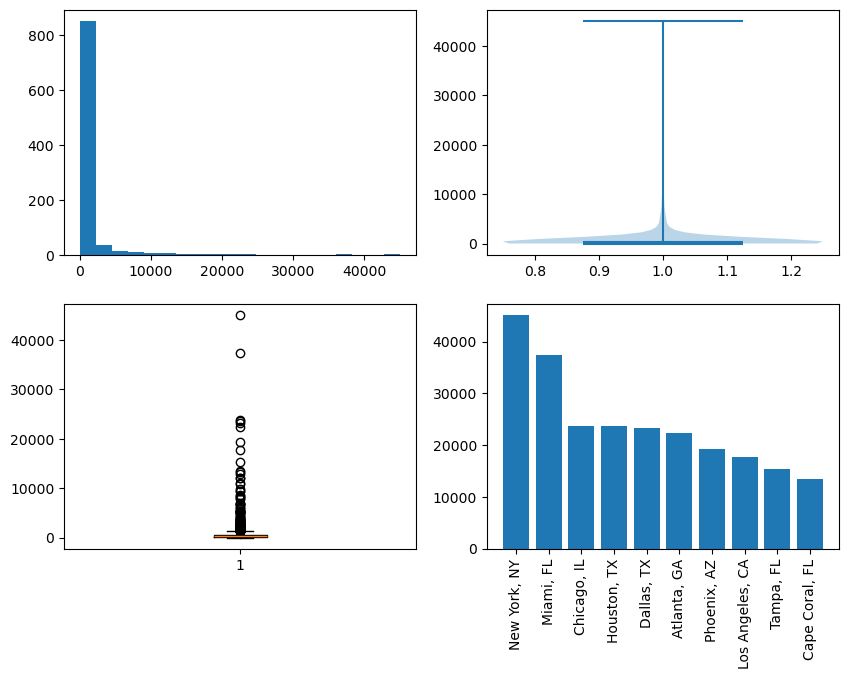

In [237]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.InventoryCount, bins=20)
    ax[0,1].violinplot(df.InventoryCount, showmedians=True)
    ax[1,0].boxplot(df.InventoryCount)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.InventoryCount.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(inventory_df_transformed
 .pipe(graph)
)

Determine how many Regions in each state have above 75th percentile in inventory count

In [238]:
inventory_df_cleaned = (inventory_df_transformed
 .query("InventoryCount > 409")   # filter dataset to only InventoryCount above 75th percentile
 .groupby(['StateName'])                     
 .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'RegionName': 'TopInventoryRegions'})
)
inventory_df_cleaned

,TopInventoryRegions
StateName,
TX,28
CA,27
FL,24
TN,13
NC,13
GA,11
MI,11
WI,10
CO,10


In [239]:
market_growth_transformed = (market_growth
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .drop(columns=['BaseDate', '2025-04-30', '2025-06-30']) # Keep only 1 year market growth forecast
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='MarketGrowth')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .drop(columns=['index', 'RegionID', 'SizeRank', 'RegionType', 'Date'])
 .set_index('StateName')
 .sort_values(by=['MarketGrowth'], ascending=False)
 .reset_index()
)

Graphs for Market Growth

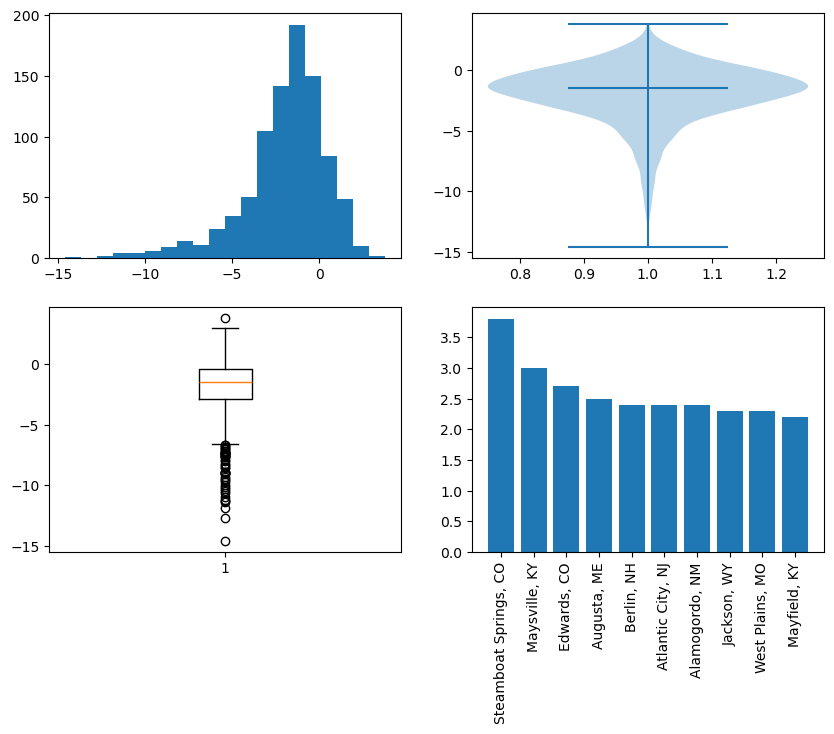

In [240]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.MarketGrowth, bins=20)
    ax[0,1].violinplot(df.MarketGrowth, showmedians=True)
    ax[1,0].boxplot(df.MarketGrowth)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.MarketGrowth.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(market_growth_transformed
 .pipe(graph)
)

Determine how many Regions in each state have a positive market growth

In [241]:
market_growth_df_cleaned = (market_growth_transformed
 .query("MarketGrowth > 0") # filter dataset to only markets that are growing
 .groupby(['StateName'])
 .agg({'RegionName': 'count'})  # Count the number of RegionNames that are growing in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'RegionName': 'TopGrowthRegions'})
)
market_growth_df_cleaned

,TopGrowthRegions
StateName,
NC,20
NY,11
GA,11
OH,10
KY,9
WI,8
IN,8
TN,7
ID,6


In [242]:
home_value_df_transformed = (home_value_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .interpolate(axis=0, limit_direction='forward') # Use linear interpolation to impute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='HomeValue')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")  # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'HomeValue': 'mean'})  # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['HomeValue'], ascending=False)
 .reset_index()
)

C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\2388933982.py:3: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward') # Use linear interpolation to impute missing values


Graphs for Home Value

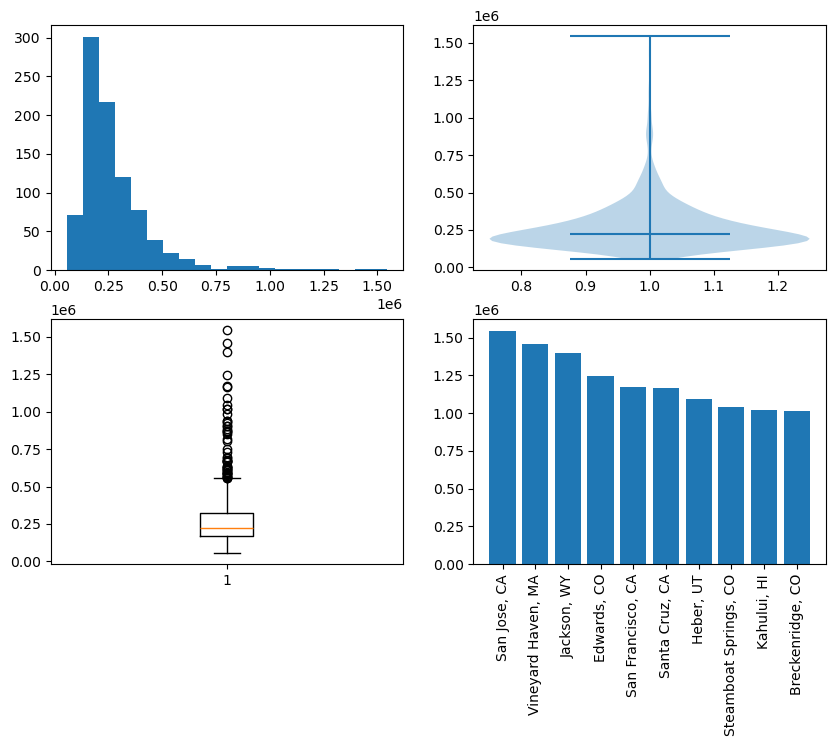

In [243]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.HomeValue, bins=20)
    ax[0,1].violinplot(df.HomeValue, showmedians=True)
    ax[1,0].boxplot(df.HomeValue)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.HomeValue.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(home_value_df_transformed
 .pipe(graph)
)

Determine how many Regions in each state have above 75th percentile in home value

In [244]:
home_value_df_cleaned = (home_value_df_transformed
 .query("HomeValue > 301336")  # filter dataset to only SalesCount above 75th percentile
 .groupby(['StateName'])                     
 .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'RegionName': 'TopHomeValueRegions'})
)
home_value_df_cleaned

,TopHomeValueRegions
StateName,
CA,33
WA,19
FL,17
OR,17
CO,14
ID,13
NC,11
NV,9
UT,8


## Now we merge all the datasets into one big dataframe

In [245]:
dfs = [market_growth_df_cleaned, inventory_df_cleaned, heat_index_df_cleaned, sale_count_df_cleaned, rent_df_cleaned, home_value_df_cleaned]
df_merged_state = dfs[0]
for df in dfs[1:]:
    df_merged_state = df_merged_state.merge(df, on='StateName', how='outer')
df_merged_state

,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,TopSalesRegions,TopRentalRegions,TopHomeValueRegions
StateName,,,,,,
AK,NaN,1.0,4.0,NaN,2.0,3.0
AL,NaN,9.0,1.0,NaN,2.0,2.0
AR,3.0,6.0,NaN,NaN,1.0,1.0
AZ,3.0,8.0,1.0,1.0,3.0,6.0
CA,NaN,27.0,23.0,4.0,26.0,33.0
CO,5.0,10.0,5.0,1.0,10.0,14.0
CT,4.0,5.0,5.0,NaN,5.0,5.0
DE,NaN,1.0,1.0,NaN,1.0,2.0
FL,5.0,24.0,NaN,4.0,20.0,17.0


## 1) Show me the market trends to help me decide. Which US real-estate market is doing best overall.

### Combining all of the categories and giving them a score based on each category of them we get the following table

In [246]:
final_analysis_state = (df_merged_state
 .fillna(0)
 .assign(SummedTotals = lambda df: ((df.TopGrowthRegions + 
                                    df.TopInventoryRegions + 
                                    df.TopMarketRegions + 
                                    df.TopSalesRegions + 
                                    df.TopRentalRegions + 
                                    df.TopHomeValueRegions) / 6
                                   )
        )
 .sort_values('SummedTotals', ascending=False)
 .reset_index()
)
final_analysis_state

,StateName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,TopSalesRegions,TopRentalRegions,TopHomeValueRegions,SummedTotals
0,CA,0.0,27.0,23.0,4.0,26.0,33.0,18.833333
1,FL,5.0,24.0,0.0,4.0,20.0,17.0,11.666667
2,NC,20.0,13.0,11.0,1.0,9.0,11.0,10.833333
3,NY,11.0,10.0,19.0,1.0,7.0,5.0,8.833333
4,TX,2.0,28.0,5.0,2.0,6.0,7.0,8.333333
5,CO,5.0,10.0,5.0,1.0,10.0,14.0,7.500000
6,WA,1.0,9.0,6.0,1.0,9.0,19.0,7.500000
7,OR,1.0,8.0,7.0,1.0,8.0,17.0,7.000000
8,OH,10.0,9.0,19.0,1.0,1.0,1.0,6.833333
9,PA,3.0,10.0,18.0,2.0,3.0,4.0,6.666667


### If you remove anything that scores a 0 in any category this is what it looks like instead

In [247]:
final_analysis_cleaned_state = final_analysis_state[(final_analysis_state != 0).all(axis=1)]
final_analysis_cleaned_state

,StateName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,TopSalesRegions,TopRentalRegions,TopHomeValueRegions,SummedTotals
2,NC,20.0,13.0,11.0,1.0,9.0,11.0,10.833333
3,NY,11.0,10.0,19.0,1.0,7.0,5.0,8.833333
4,TX,2.0,28.0,5.0,2.0,6.0,7.0,8.333333
5,CO,5.0,10.0,5.0,1.0,10.0,14.0,7.500000
6,WA,1.0,9.0,6.0,1.0,9.0,19.0,7.500000
7,OR,1.0,8.0,7.0,1.0,8.0,17.0,7.000000
8,OH,10.0,9.0,19.0,1.0,1.0,1.0,6.833333
9,PA,3.0,10.0,18.0,2.0,3.0,4.0,6.666667
10,GA,11.0,11.0,3.0,1.0,7.0,5.0,6.333333
12,MI,2.0,11.0,16.0,1.0,2.0,3.0,5.833333


### We remove all the values with a 0 to find the best region for each category because we believe that the 'best choice' won't be in the bottom for any specific category

For this section we spent most of our time deliberating what each of the categories truly meant and how they compared to one another. While this section is very simple code-wise, it is the basis we used to determine what/where we would look for the rest of the project.

### Based on this curated data, we have it broken down into 4 categories:

1. Growth - We want a high number here to show that there is a lot of potential in this area

In [248]:
top_regions_growth = final_analysis_cleaned_state.sort_values(by='TopGrowthRegions', ascending=False).head(5)
top_regions_growth

,StateName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,TopSalesRegions,TopRentalRegions,TopHomeValueRegions,SummedTotals
2,NC,20.0,13.0,11.0,1.0,9.0,11.0,10.833333
3,NY,11.0,10.0,19.0,1.0,7.0,5.0,8.833333
10,GA,11.0,11.0,3.0,1.0,7.0,5.0,6.333333
8,OH,10.0,9.0,19.0,1.0,1.0,1.0,6.833333
16,TN,7.0,13.0,1.0,1.0,2.0,5.0,4.833333


2. Rental - We potentially want a high number here because it could mean that we can make a lot of money per month. It does not mean that the highest is the best, but it does mean that there is a high ceiling for potential earnings

In [249]:
top_regions_rentals = final_analysis_cleaned_state.sort_values(by='TopRentalRegions', ascending=False).head(5)
top_regions_rentals

,StateName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,TopSalesRegions,TopRentalRegions,TopHomeValueRegions,SummedTotals
5,CO,5.0,10.0,5.0,1.0,10.0,14.0,7.500000
2,NC,20.0,13.0,11.0,1.0,9.0,11.0,10.833333
6,WA,1.0,9.0,6.0,1.0,9.0,19.0,7.500000
7,OR,1.0,8.0,7.0,1.0,8.0,17.0,7.000000
3,NY,11.0,10.0,19.0,1.0,7.0,5.0,8.833333


3. Inventory - We want a middling number here, anything that's too high means that there is much higher supply than demand, potentially anything in the range of 8-15 is good here

In [250]:
top_regions_inventory = final_analysis_cleaned_state.sort_values(by='TopInventoryRegions', ascending=False).head(5)
top_regions_inventory

,StateName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,TopSalesRegions,TopRentalRegions,TopHomeValueRegions,SummedTotals
4,TX,2.0,28.0,5.0,2.0,6.0,7.0,8.333333
2,NC,20.0,13.0,11.0,1.0,9.0,11.0,10.833333
16,TN,7.0,13.0,1.0,1.0,2.0,5.0,4.833333
10,GA,11.0,11.0,3.0,1.0,7.0,5.0,6.333333
12,MI,2.0,11.0,16.0,1.0,2.0,3.0,5.833333


4. Market Heat - This is showing if the market is a buyers market or a sellers market. A lower number here means that it is better for the buyer, which means it could be a good time to invest depending on the other factors

In [251]:
top_regions_heat = final_analysis_cleaned_state.sort_values(by='TopMarketRegions', ascending=True).head(10)
top_regions_heat

,StateName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,TopSalesRegions,TopRentalRegions,TopHomeValueRegions,SummedTotals
16,TN,7.0,13.0,1.0,1.0,2.0,5.0,4.833333
21,AZ,3.0,8.0,1.0,1.0,3.0,6.0,3.666667
10,GA,11.0,11.0,3.0,1.0,7.0,5.0,6.333333
4,TX,2.0,28.0,5.0,2.0,6.0,7.0,8.333333
5,CO,5.0,10.0,5.0,1.0,10.0,14.0,7.500000
18,MA,3.0,5.0,5.0,1.0,5.0,6.0,4.166667
6,WA,1.0,9.0,6.0,1.0,9.0,19.0,7.500000
7,OR,1.0,8.0,7.0,1.0,8.0,17.0,7.000000
2,NC,20.0,13.0,11.0,1.0,9.0,11.0,10.833333
13,VA,1.0,6.0,12.0,2.0,7.0,6.0,5.666667


Showing all of them together we can visualize it as

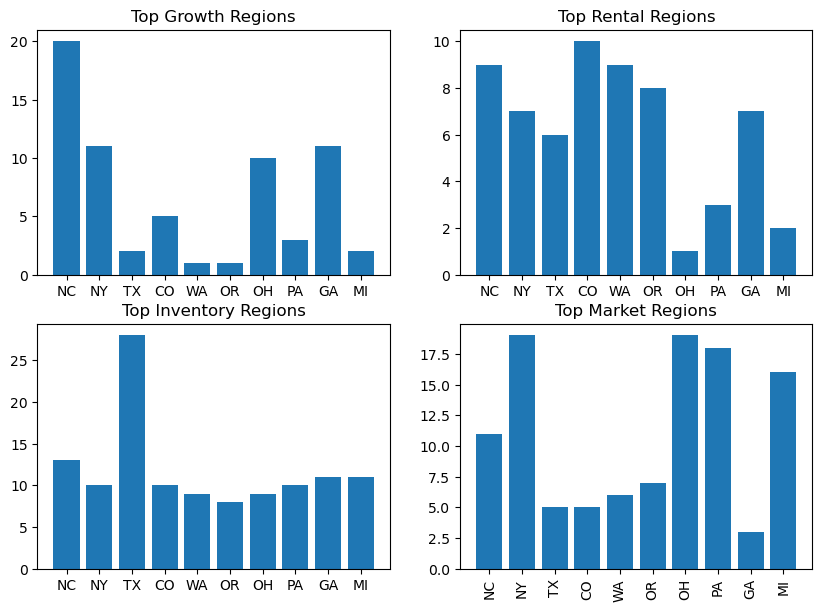

In [252]:
def graph(df):
    fig, ax = plt.subplots(2,2,figsize=(10,7))
    ax[0,0].bar(x=df.StateName.head(10), height=df.TopGrowthRegions.head(10))
    ax[0,1].bar(x=df.StateName.head(10), height=df.TopRentalRegions.head(10))
    ax[1,0].bar(x=df.StateName.head(10), height=df.TopInventoryRegions.head(10))
    ax[1,1].bar(x=df.StateName.head(10), height=df.TopMarketRegions.head(10))
    ax[0,0].set_title("Top Growth Regions")
    ax[0,1].set_title("Top Rental Regions")
    ax[1,0].set_title("Top Inventory Regions")
    ax[1,1].set_title("Top Market Regions")
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(final_analysis_cleaned_state
 .pipe(graph)
)

## Based on these categories our recommendation is that North Carolina and Colorado are potentially the best states to invest in currently (not financial advice)

### At this point we can look at the data with the lense of specific regions from North Carolina and Colorado to see what kind of results that might give us

Unfortunately we have to basically redo all of the work from before to reevaluate it by RegionName (city)

In [253]:
# transform dataset
rent_df_transformed = (rent_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .interpolate(axis=0, limit_direction='forward') # Use linear interpolation to inpute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='RentalPrice') # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .sort_values(by=['Date'], ascending=False)
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'") # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'RentalPrice': 'mean'}) # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['RentalPrice'], ascending=False)
 .reset_index()
 .assign(zscore = lambda df: sp.zscore(df.RentalPrice)).round(3)
)
# clean
rent_df_cleaned = (rent_df_transformed
 .query("zscore < 3")  # filter dataset to only RentalPrices above 75th percentile
 # .query("zscore > 1.5")
 # .groupby(['RegionName'])
 # .agg({'RegionName': 'count'}) # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'zscore': 'TopRentalRegions'})
 .drop(columns=['RentalPrice'])
)
# transform dataset
sale_count_df_transformed = (sale_count_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US          
 .interpolate(axis=0, limit_direction='forward')  # Use linear interpolation to inpute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='SaleCount')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .sort_values(by=['Date'], ascending=False)
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")  # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'SaleCount': 'mean'})  # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['SaleCount'], ascending=False)
 .reset_index()
 .assign(zscore = lambda df: sp.zscore(df.SaleCount)).round(3)
)
# clean
sale_count_df_cleaned = (sale_count_df_transformed
 # .query("SaleCount > 2234")  # filter dataset to only SalesCount above 75th percentile
 .query("zscore < 3")  # filter dataset to only RentalPrices above 75th percentile
 # .query("zscore > 1.5")
 # .groupby(['StateName'])
 # .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'zscore': 'TopSalesRegions'})
 .drop(columns=['SaleCount'])  
)
# transform dataset
heat_index_df_transformed = (heat_index_df
 .dropna(subset=['StateName'])
 .interpolate(axis=0, limit_direction='forward')
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='IndexScore')
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")
 .groupby(['StateName', 'RegionName'])
 .agg({'IndexScore': 'mean'})
 .sort_values(by=['IndexScore'], ascending=False)
 .reset_index()
 .assign(zscore = lambda df: sp.zscore(df.IndexScore)).round(3)
)
# clean
heat_index_df_cleaned = (heat_index_df_transformed
 # .query("IndexScore > 59") # filter dataset to only SalesCount above 75th percentile
 .query("zscore < 3")  # filter dataset to only RentalPrices above 75th percentile
 # .query("zscore > 1.5")
 # .groupby(['StateName'])
 # .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'zscore': 'TopMarketRegions'})
 .drop(columns=['IndexScore', 'StateName'])
)
# transform dataset
inventory_df_transformed = (inventory_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .interpolate(axis=0, limit_direction='forward')  # Use linear interpolation to impute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='InventoryCount')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")  # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'InventoryCount': 'mean'})  # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['InventoryCount'], ascending=False)
 .reset_index()
 .assign(zscore = lambda df: sp.zscore(df.InventoryCount)).round(3)
)
# clean
inventory_df_cleaned = (inventory_df_transformed
 # .query("InventoryCount > 409")   # filter dataset to only InventoryCount above 75th percentile
 .query("zscore < 3")  # filter dataset to only RentalPrices above 75th percentile
 .query("zscore < 1.5")
 # .groupby(['StateName'])                     
 # .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'zscore': 'TopInventoryRegions'})
 .drop(columns=['InventoryCount', 'StateName'])
)
# transform dataset
market_growth_transformed = (market_growth
 .dropna(subset=['StateName'])  # Remove missing state names
 .drop(columns=['BaseDate', '2025-04-30', '2025-06-30'])  # Keep relevant columns
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='MarketGrowth')  # Reshape
 .astype({'Date': 'datetime64[ns]'})  # Convert Date to datetime
 .reset_index()
 .drop(columns=['index', 'RegionID', 'SizeRank', 'RegionType', 'Date'])  # Clean up unnecessary columns
 .groupby(['StateName', 'RegionName'])
 .agg({'MarketGrowth': 'mean'})  # Aggregate to get mean market growth
 .reset_index()  # Convert back to a normal DataFrame
 .sort_values(by=['MarketGrowth'], ascending=False)  # Now sorting works!
 .assign(zscore=lambda df: sp.zscore(df.MarketGrowth))  # Add z-score
 .round(3)  # Round values for clarity
)
# clean
market_growth_df_cleaned = (market_growth_transformed
 .query("zscore < 3")  # filter dataset to only RentalPrices above 75th percentile                       
 # # .query("zscore > 1.5")
 .query("MarketGrowth > 0") # filter dataset to only markets that are growing
 # .groupby(['StateName'])
 # .agg({'RegionName': 'count'})  # Count the number of RegionNames that are growing in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'zscore': 'TopGrowthRegions'})
 .drop(columns=['MarketGrowth', 'StateName'])
)
# transform dataset
home_value_df_transformed = (home_value_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .interpolate(axis=0, limit_direction='forward') # Use linear interpolation to impute missing values
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='HomeValue')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .drop(columns=['index'])
 .query("Date >= '2022-3-31'")  # limit dataset to last 3 years
 .groupby(['StateName', 'RegionName'])
 .agg({'HomeValue': 'mean'})  # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['HomeValue'], ascending=False)
 .reset_index()
 .assign(zscore = lambda df: sp.zscore(df.HomeValue)).round(3)
)
# clean
# Determine how many Regions in each state have above 75th percentile in home value
home_value_df_cleaned = (home_value_df_transformed
 # .query("HomeValue > 301336")  # filter dataset to only HomeValue above 75th percentile
 .query("zscore < 3")  # filter dataset to only RentalPrices above 75th percentile
 # .query("zscore > 1.5")
 # .groupby(['StateName'])                     
 # .agg({'RegionName': 'count'})  # Count the number of RegionNames that are above 75th percentile in each state
 .sort_values('RegionName', ascending=False)
 .rename(columns={'zscore': 'TopHomeValueRegions'})
 .drop(columns=['HomeValue', 'StateName'])
)
# Combine all the datasets
dfs = [market_growth_df_cleaned, inventory_df_cleaned,heat_index_df_cleaned, sale_count_df_cleaned, rent_df_cleaned, home_value_df_cleaned]
df_merged_all = dfs[0]
for df in dfs[1:]:
    df_merged_all = df_merged_all.merge(df, on='RegionName', how='outer')
df_merged_all

C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\564074022.py:4: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward') # Use linear interpolation to inpute missing values
C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\564074022.py:30: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward')  # Use linear interpolation to inpute missing values
C:\Users\MattB\AppData\Local\Temp\ipykernel_63880\564074022.py:57: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  .interpolate(axis=0, limit_direction='forward')
C:\Users\MattB\AppData\Local\Temp\i

,RegionName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,StateName_x,TopSalesRegions,StateName_y,TopRentalRegions,TopHomeValueRegions
0,"Aberdeen, SD",NaN,-0.292,0.013,NaN,NaN,NaN,NaN,-0.357
1,"Aberdeen, WA",NaN,-0.162,-1.159,NaN,NaN,WA,-0.365,0.271
2,"Abilene, TX",NaN,-0.085,-0.390,NaN,NaN,TX,-0.433,-0.504
3,"Ada, OK",NaN,-0.284,-1.098,NaN,NaN,NaN,NaN,-0.613
4,"Adrian, MI",NaN,-0.223,-0.295,NaN,NaN,NaN,NaN,-0.362
...,...,...,...,...,...,...,...,...,...
922,"Youngstown, OH",0.923,0.101,-0.041,NaN,NaN,OH,-1.229,-0.738
923,"Yuba City, CA",NaN,-0.188,0.538,NaN,NaN,CA,0.781,0.855
924,"Yuma, AZ",1.087,-0.125,0.045,NaN,NaN,AZ,-0.099,-0.030
925,"Zanesville, OH",0.923,-0.264,0.119,NaN,NaN,OH,-0.536,-0.549


In [254]:
# Take average of the count of regions from each variable
final_analysis = (df_merged_all
 .fillna(-3)
 .assign(AVGTotals = lambda df: ((df.TopGrowthRegions + 
                                    df.TopInventoryRegions + 
                                    df.TopMarketRegions + 
                                    df.TopSalesRegions + 
                                    df.TopRentalRegions + 
                                    df.TopHomeValueRegions) / 6
                                   )
        )
 .reset_index()
 .assign(State = lambda df: (df.RegionName.str[-2:]))
 .query("State == 'NC' or State == 'CO'")
 .sort_values('AVGTotals', ascending=False)                 
 # .replace(0,None)
 # .dropna()
 # .reset_index()
 # .drop(columns=['index'])
 .head(25)
)
final_analysis

,index,RegionName,TopGrowthRegions,TopInventoryRegions,TopMarketRegions,StateName_x,TopSalesRegions,StateName_y,TopRentalRegions,TopHomeValueRegions,AVGTotals,State
240,240,"Durango, CO",0.882,-0.215,-0.118,-3,-3.000,CO,1.097,2.041,0.114500,CO
663,663,"Pinehurst, NC",1.210,-0.188,0.484,-3,-3.000,NC,0.977,0.649,0.022000,NC
695,695,"Raleigh, NC",-3.000,0.709,1.149,NC,-0.322,NC,0.610,0.947,0.015500,NC
906,906,"Wilmington, NC",0.923,0.033,0.233,-3,-3.000,NC,0.512,0.790,-0.084833,NC
179,179,"Colorado Springs, CO",-3.000,0.632,0.502,CO,-0.552,CO,0.794,1.087,-0.089500,CO
295,295,"Fort Collins, CO",-3.000,0.149,0.477,CO,-0.825,CO,0.965,1.614,-0.103333,CO
104,104,"Boulder, CO",-3.000,0.052,0.511,-3,-3.000,CO,1.756,2.735,-0.157667,CO
562,562,"Morehead City, NC",0.841,-0.199,-0.308,-3,-3.000,NC,0.714,0.910,-0.173667,NC
242,242,"Durham, NC",-3.000,0.125,1.049,NC,-0.701,NC,0.495,0.726,-0.217667,NC
283,283,"Fayetteville, NC",1.087,0.151,0.812,-3,-3.000,NC,-0.134,-0.267,-0.225167,NC


Some cute graphs for fun

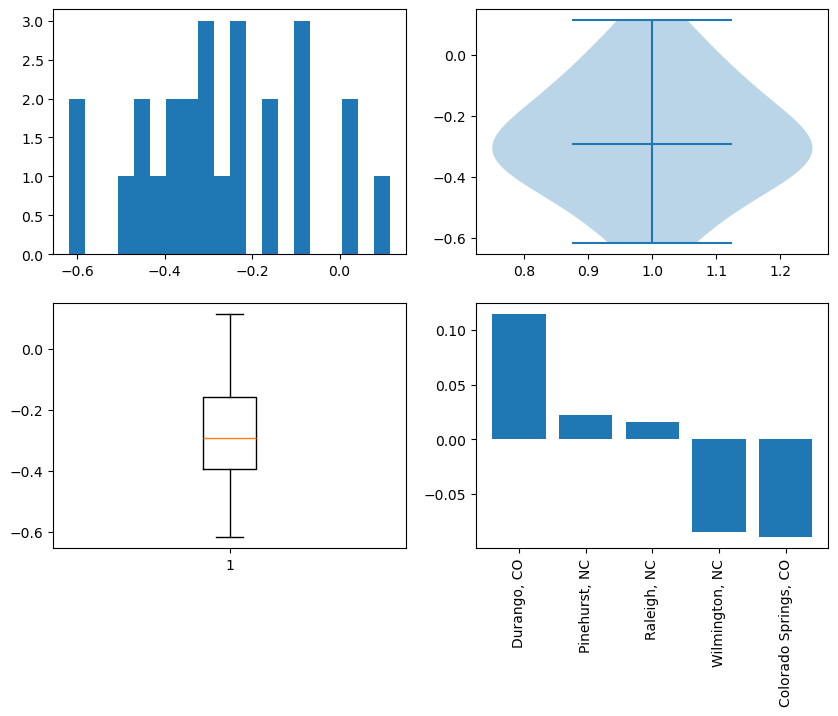

In [255]:
# Graphs for Final Analysis
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.AVGTotals, bins=20)
    ax[0,1].violinplot(df.AVGTotals, showmedians=True)
    ax[1,0].boxplot(df.AVGTotals)
    ax[1,1].bar(x=df.RegionName.head(5), height=df.AVGTotals.head(5))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(final_analysis
 .pipe(graph)
)

## 2) Are the sale prices and inventory listing going up or down overall in the US?

### We first addressed the question overall for the US, combining Sales Price and Inventory on the same plot to make a quick and easy visual analysis.

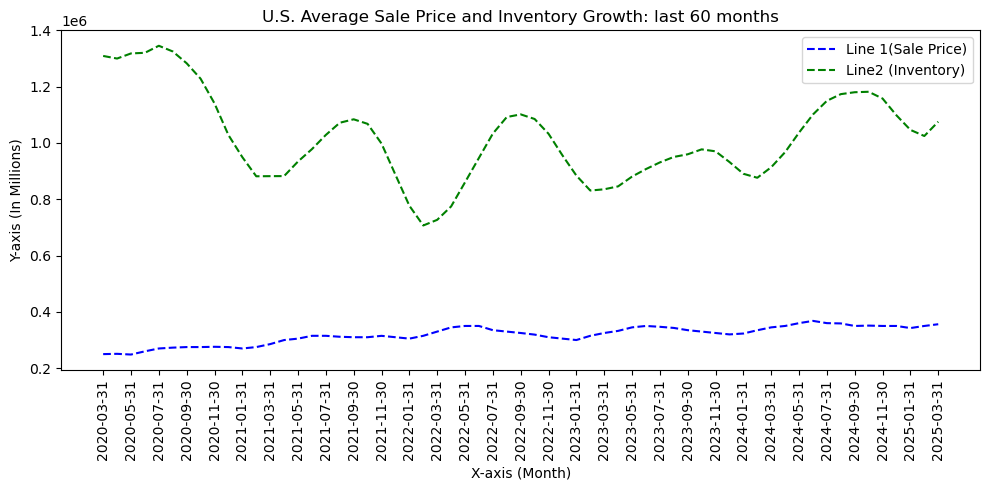

In [256]:
x_values = price_df.columns[-61:]
y1_values = price_df.iloc[0,-61:]
y2_values = inventory_df.iloc[0,-61:]


plt.figure(figsize=(10,5))
plt.plot(x_values, y1_values, 'b--', label = 'Line 1(Sale Price)')
plt.plot(x_values, y2_values, 'g--', label = 'Line2 (Inventory)')
plt.xlabel('X-axis (Month)')
plt.ylabel('Y-axis (In Millions)')
plt.title('U.S. Average Sale Price and Inventory Growth: last 60 months')
plt.xticks(x_values[::2],rotation=90)  # Rotate if x labels are long
plt.legend()
plt.tight_layout()
plt.show()

### The visualization shows that inventory in the U.S. (in green) has bounced up and down over the past 5 years and is currently lower than it was 5 years ago.  Average sales price has slowly and steadily increased.

### Looking at the data across the US only tells a broad story. We then looked at similar graphs for regions that showed the greatest investment potential based on the analysis in question 1. The states we considered were North Carolina and Colorado. In anticipation of future ROI analysis, we added a 12 month forecast (simple linear regression) based on the 60 months of data reflected in the graph

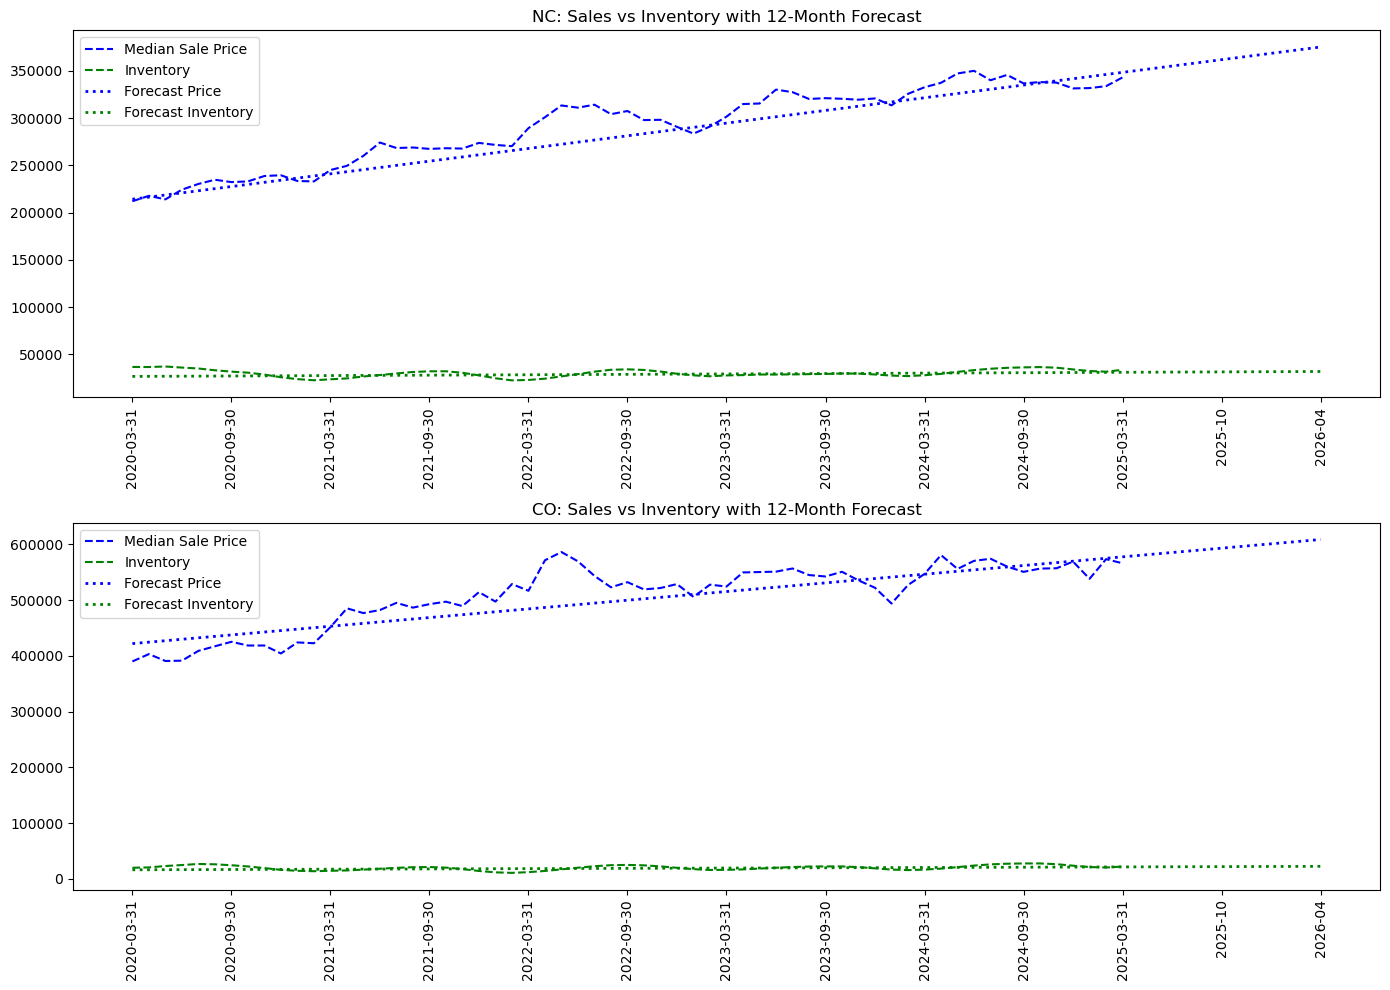

In [257]:
states = ['NC', 'CO']
x_values = price_df.columns[-61:]  # Last 61 months (assumed to be datetime-like strings)
x_numeric = np.arange(len(x_values))  # Turn time axis into numeric for regression

# Prepare future months
future_months = 12
future_x_numeric = np.arange(len(x_values) + future_months)
future_labels = pd.date_range(start=pd.to_datetime(x_values[-1]) + pd.DateOffset(months=1),
                              periods=future_months, freq='MS').strftime('%Y-%m').tolist()
full_x_labels = list(x_values) + future_labels
 
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
axes = axes.flatten()
 
for i, state in enumerate(states):
    ax = axes[i]
    y1_values = price_df.query(f"StateName == '{state}'")[x_values].mean().values
    y2_values = inventory_df.query(f"StateName == '{state}'")[x_values].sum().values
 
    # Rolling averages
    y1_series = pd.Series(y1_values).rolling(window=12).mean()
    y2_series = pd.Series(y2_values).rolling(window=12).mean()
 
    # Fit linear regression on non-NaN values (due to rolling window)
    valid_idx = ~y1_series.isna()
    X_train = x_numeric[valid_idx].reshape(-1, 1)
    y1_train = y1_series[valid_idx].values
    y2_train = y2_series[valid_idx].values
 
    model1 = LinearRegression().fit(X_train, y1_train)
    model2 = LinearRegression().fit(X_train, y2_train)
 
    y1_forecast = model1.predict(future_x_numeric.reshape(-1, 1))
    y2_forecast = model2.predict(future_x_numeric.reshape(-1, 1))
 
    # Plot historical data
    ax.plot(x_values, y1_values, 'b--', label='Median Sale Price')
    ax.plot(x_values, y2_values, 'g--', label='Inventory')
    #ax.plot(x_values, y1_series, 'b-', linewidth=2, label='12-mo Avg Price')
    #ax.plot(x_values, y2_series, 'g-', linewidth=2, label='12-mo Avg Inventory')
 
    # Plot forecast lines
    ax.plot(full_x_labels, y1_forecast, 'b:', linewidth=2, label='Forecast Price')
    ax.plot(full_x_labels, y2_forecast, 'g:', linewidth=2, label='Forecast Inventory')
 
    ax.set_title(f"{state}: Sales vs Inventory with 12-Month Forecast")
    ax.set_xticks(full_x_labels[::6])  # Show every 6 months
    ax.tick_params(axis='x', rotation=90)
    ax.legend()
 
plt.tight_layout()
plt.show()

### These graphs confirmed that both states were viable investments in terms of rising sale prices and fairly static inventory (to prevent decreasing values due to an inventory glut). It is notable the sale price ranges differ significantly, with less outlay required to invest in North Carolina properties (starting just over 200k) vs. Colorado properties (400k +)  

## 3) Should I wait to invest or should I invest now and if so then where should I invest. (You could recommend more than one place)?

# TEMPORARY SECTION
Faiyak to use a line graph/forecast/etc to show the current trending of the market

In [258]:
display(market_growth)

,RegionID,SizeRank,RegionName,RegionType,StateName,BaseDate,2025-04-30,2025-06-30,2026-03-31
0,102001,0,United States,country,NaN,2025-03-31,-0.3,-0.9,-1.7
1,394913,1,"New York, NY",msa,NY,2025-03-31,0.0,-0.6,-2.4
2,753899,2,"Los Angeles, CA",msa,CA,2025-03-31,-0.4,-1.0,-1.9
3,394463,3,"Chicago, IL",msa,IL,2025-03-31,0.0,-0.6,-1.9
4,394514,4,"Dallas, TX",msa,TX,2025-03-31,-0.6,-1.7,-2.9
...,...,...,...,...,...,...,...,...,...
890,753929,935,"Zapata, TX",msa,TX,2025-03-31,-0.9,-2.7,-9.5
891,394743,936,"Ketchikan, AK",msa,AK,2025-03-31,-0.2,-1.2,-5.3
892,753874,937,"Craig, CO",msa,CO,2025-03-31,0.2,0.1,0.6
893,395188,938,"Vernon, TX",msa,TX,2025-03-31,-1.8,-4.5,-9.7


Since the investor plans to buy, flip and sell/rent the house, we are focusing on the 1 year forecasted value

In [259]:
market_growth_sorted = market_growth.sort_values(by='2026-03-31', ascending=False)
print(market_growth_sorted)

     RegionID  SizeRank             RegionName RegionType StateName  \
832    753921       867  Steamboat Springs, CO        msa        CO   
881    394841       925          Maysville, KY        msa        KY   
549    394556       566            Edwards, CO        msa        CO   
329    394353       339            Augusta, ME        msa        ME   
777    394383       805             Berlin, NH        msa        NH   
..        ...       ...                    ...        ...       ...   
591    394316       609              Alice, TX        msa        TX   
745    394385       770         Big Spring, TX        msa        TX   
778    394473       806          Cleveland, MS        msa        MS   
889    394968       934              Pecos, TX        msa        TX   
630    394650       648         Greenville, MS        msa        MS   

       BaseDate  2025-04-30  2025-06-30  2026-03-31  
832  2025-03-31         0.2         0.8         3.8  
881  2025-03-31         1.2         1.4

In [260]:
# Count positive values
column_name = '2026-03-31'
# Count positive values
positive_count = (market_growth[column_name] > 0).sum()

# Count negative values
negative_count = (market_growth[column_name] < 0).sum()

print(f"Positive values in '{column_name}': {positive_count}")
print(f"Negative values in '{column_name}': {negative_count}")

Positive values in '2026-03-31': 157
Negative values in '2026-03-31': 725


157 MSAs have positive growth projections over the course of 1 year. While the rest 725 MSA have a negative growth projection i.e. a declining projection over the next 1 year. As a next step, we wanted to see which MSAs have positive growth, and map those in a barchart. 

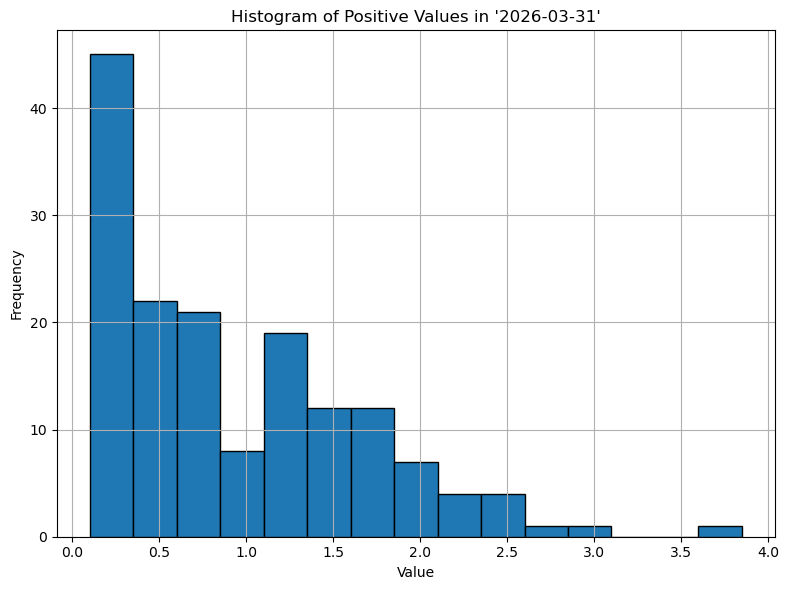

In [261]:
# Filter positive values
positive_values = market_growth[market_growth[column_name] > 0][column_name]

# Check if there are positive values to plot
if not positive_values.empty:
    # Define bin width
    bin_width = 0.25

    # Calculate bin edges
    min_val = positive_values.min()
    max_val = positive_values.max()
    bins = np.arange(min_val, max_val + bin_width, bin_width)

    # Plot histogram
    plt.figure(figsize=(8, 6))
    plt.hist(positive_values, bins=bins, edgecolor='black')
    plt.title(f"Histogram of Positive Values in '{column_name}'")
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print(f"No positive values found in column '{column_name}'.")

From this visual, we can see the distributio of all the the MSAs with poisitive growth projection. As a next step, we wanted to focus on the >2 regions. 

In [262]:
filtered_region_names = market_growth.loc[market_growth['2026-03-31'] >= 2, 'RegionName']

In [263]:
print(filtered_region_names)

176        Atlantic City, NJ
329              Augusta, ME
478           Alamogordo, NM
549              Edwards, CO
681          West Plains, MO
721             Mayfield, KY
744              Jackson, WY
747           Dodge City, KS
777               Berlin, NH
810            Thomaston, GA
832    Steamboat Springs, CO
881            Maysville, KY
Name: RegionName, dtype: object


In [264]:
column_name = '2026-03-31'
filtered_df = market_growth[market_growth[column_name] >= 2]

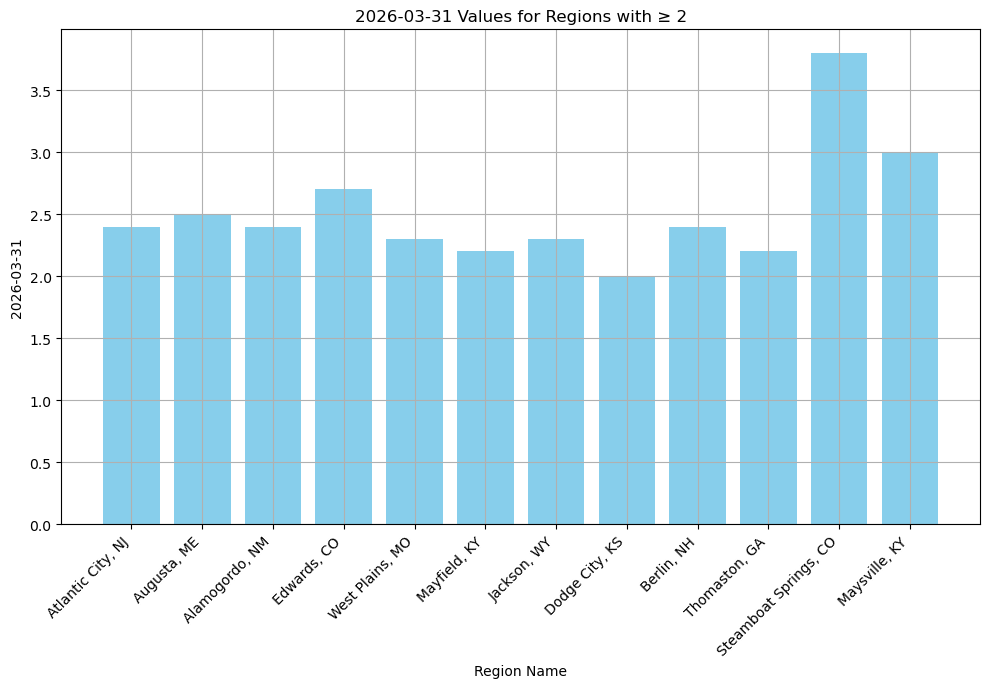

In [265]:
plt.figure(figsize=(10, 6))
plt.xlabel('Region Name')
plt.ylabel(column_name)
plt.title(f'{column_name} Values for Regions with ≥ 2')
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
bars = plt.bar(filtered_df['RegionName'], filtered_df[column_name], color='skyblue')
plt.show()

### This chart shows that regions that have the highest growth forecast in the next 1 year. 
As a next step, we looked the difference in growth projection from the start to the end point and sorted them in descending order. next we grouped them by state to identify to state wise trend

In [266]:
market_growth['Difference'] = market_growth['2026-03-31']- market_growth['2025-04-30']
market_growth_sorted = market_growth.sort_values(by='Difference', ascending=False)
print(market_growth_sorted)

     RegionID  SizeRank             RegionName RegionType StateName  \
832    753921       867  Steamboat Springs, CO        msa        CO   
549    394556       566            Edwards, CO        msa        CO   
810    395154       843          Thomaston, GA        msa        GA   
329    394353       339            Augusta, ME        msa        ME   
777    394383       805             Berlin, NH        msa        NH   
..        ...       ...                    ...        ...       ...   
468    394683       481              Hobbs, NM        msa        NM   
745    394385       770         Big Spring, TX        msa        TX   
778    394473       806          Cleveland, MS        msa        MS   
889    394968       934              Pecos, TX        msa        TX   
630    394650       648         Greenville, MS        msa        MS   

       BaseDate  2025-04-30  2025-06-30  2026-03-31  Difference  
832  2025-03-31         0.2         0.8         3.8         3.6  
549  2025-03-31

In [267]:
# Group by 'StateName' and calculate the mean of 'Difference'
average_difference = market_growth.groupby('StateName')['Difference'].mean().reset_index()

# Sort by 'Difference' in descending order
sorted_ad = average_difference.sort_values(by='Difference', ascending=False)

# Display the sorted DataFrame
print(sorted_ad)

   StateName  Difference
29        NH    1.660000
20        ME    1.525000
30        NJ    1.250000
6         CT    0.760000
25        MT    0.728571
12        ID    0.169231
18        MA    0.116667
26        NC    0.086486
38        RI   -0.100000
33        NY   -0.223077
41        TN   -0.323077
9         GA   -0.324324
43        UT   -0.355556
14        IN   -0.358333
3         AZ   -0.410000
16        KY   -0.520000
47        WI   -0.526087
8         FL   -0.710345
7         DE   -0.800000
45        VT   -0.825000
34        OH   -0.952273
44        VA   -1.035714
5         CO   -1.105882
15        KS   -1.316667
49        WY   -1.422222
23        MO   -1.476000
28        NE   -1.541667
36        OR   -1.555000
10        HI   -1.600000
46        WA   -1.605000
21        MI   -1.683871
35        OK   -1.700000
39        SC   -1.746667
22        MN   -1.804762
40        SD   -1.827273
32        NV   -1.844444
19        MD   -1.883333
37        PA   -2.158824
1         AL   -2.265000


### We can see some of states came up as positive based on the average of different MSAs in the state. 
Next to help us to specify the growth projections of a specific regions in a state, we wanted to create a barchart that will show the growth projections over the next 1 year based on the starting point. The below 2 graphs are for our selected state North Carolina and Colarado. 

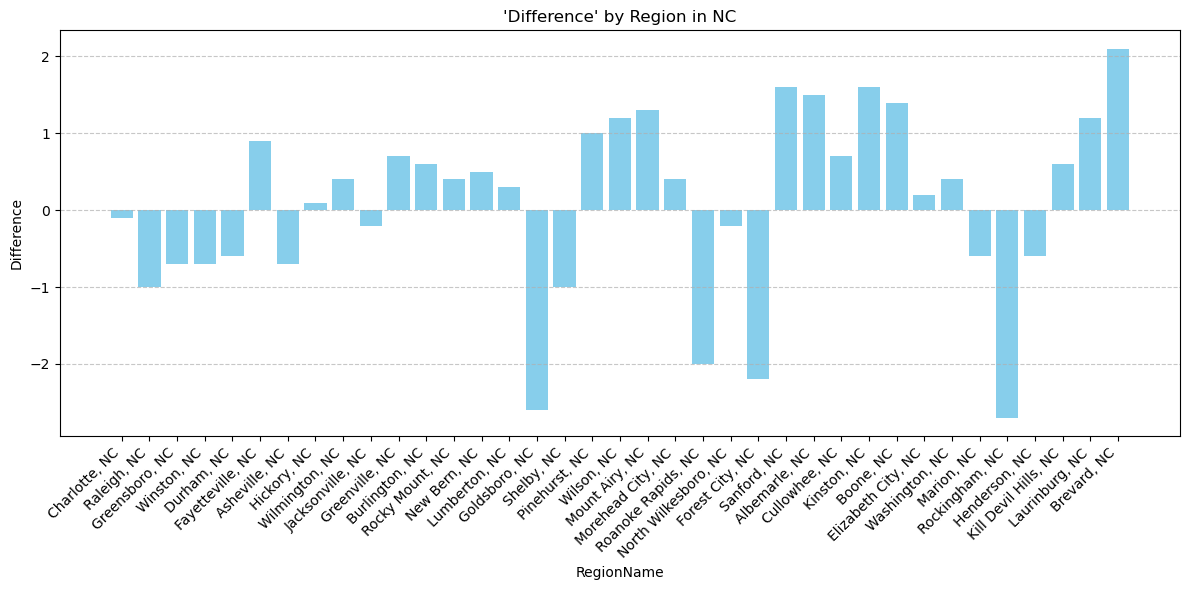

In [268]:
# Replace 'NC' with your desired state name
state_name = 'NC'

# Filter the DataFrame for the specified state
filtered_df = market_growth[market_growth['StateName'] == state_name]

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(filtered_df['RegionName'], filtered_df['Difference'], color='skyblue')
plt.title(f"'Difference' by Region in {state_name}")
plt.xlabel('RegionName')
plt.ylabel('Difference')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add horizontal grid lines
plt.show()

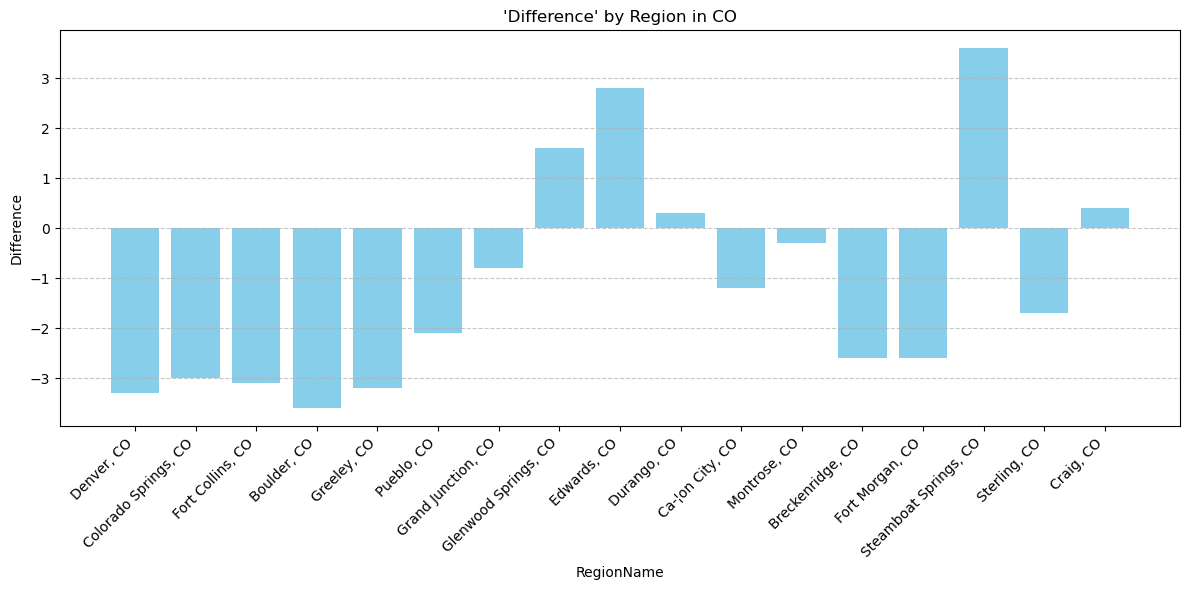

In [269]:
# Replace 'NC' with your desired state name
state_name = 'CO'

# Filter the DataFrame for the specified state
filtered_df = market_growth[market_growth['StateName'] == state_name]

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(filtered_df['RegionName'], filtered_df['Difference'], color='skyblue')
plt.title(f"'Difference' by Region in {state_name}")
plt.xlabel('RegionName')
plt.ylabel('Difference')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add horizontal grid lines
plt.show()

## 4) How long some of the real-estate stays on the market before they rent or sell?

# TEMPORARY SECTION
Carnes to create a Histogram for this. For extra credit we can show our top contenders in a bar chart as well

### We used the "Days to Pending" dataset. Specifically it was the "Mean Days to Pending (Smooth, All Homes, Monthly)" for Metro & US. We chose to use this dataset as we felt that the days to pending would better represent how long real-estate is spending on the market than the "Days to Close" or finding a way to combine the two. We thought the median value would give us a better true reprentation than the mean values due to the effect from outliers on the mean. For all of our datasets we tried to use monthly values for all homes and used Metro & US as the geography. The first step we took was to use the describe method to get a rough overview of the data. Then we adjusted the index to be the Region Name for ease of accessing and visualizing the data ###

In [270]:
days_to_pending = pd.read_csv('Metro_med_doz_pending_uc_sfrcondo_sm_month.csv')
days_to_pending.describe()
days_to_pending = days_to_pending.set_index('RegionName')
days_to_pending.head()

,RegionID,SizeRank,RegionType,StateName,2018-03-31,2018-04-30,2018-05-31,2018-06-30,2018-07-31,2018-08-31,...,2024-06-30,2024-07-31,2024-08-31,2024-09-30,2024-10-31,2024-11-30,2024-12-31,2025-01-31,2025-02-28,2025-03-31
RegionName,,,,,,,,,,,,,,,,,,,,,
United States,102001,0,country,NaN,31.0,21.0,19.0,18.0,20.0,22.0,...,14.0,15.0,18.0,20.0,21.0,24.0,29.0,34.0,33.0,26.0
"New York, NY",394913,1,msa,NY,58.0,43.0,38.0,40.0,43.0,48.0,...,22.0,24.0,26.0,28.0,28.0,30.0,34.0,39.0,37.0,31.0
"Los Angeles, CA",753899,2,msa,CA,17.0,14.0,15.0,15.0,17.0,19.0,...,14.0,15.0,16.0,18.0,20.0,22.0,25.0,26.0,24.0,20.0
"Chicago, IL",394463,3,msa,IL,32.0,17.0,15.0,16.0,18.0,21.0,...,7.0,8.0,9.0,11.0,13.0,16.0,20.0,22.0,20.0,14.0
"Dallas, TX",394514,4,msa,TX,27.0,21.0,20.0,20.0,22.0,25.0,...,17.0,20.0,25.0,30.0,33.0,34.0,39.0,45.0,43.0,35.0


### Next we checked to see if there were any null values in the timepoint we were going to look at first

In [271]:
days_to_pending['2025-03-31'].isnull().sum()

0

### We then removed the "United States" value from the dataset as this is an overall average of all other datapoints and is not needed

In [272]:
days_to_pending = days_to_pending.drop(["United States"])

### This step grouped the data by state and found the average days to pending in each state for later graphical analysis ###

In [273]:
days_pend_group = days_to_pending.groupby("StateName")["2025-03-31"].mean()
days_pend_group

StateName
AK    17.666667
AL    40.523810
AR    50.454545
AZ    40.363636
CA    24.133333
CO    37.066667
CT    10.800000
DE    26.500000
FL    50.142857
GA    38.615385
HI    49.500000
IA    43.200000
ID    39.833333
IL    21.037037
IN    30.482759
KS    30.866667
KY    42.200000
LA    58.133333
MA    19.400000
MD    23.166667
ME    21.000000
MI    30.153846
MN    36.058824
MO    32.000000
MS    41.500000
MT    43.500000
NC    32.093750
ND    30.000000
NE    34.000000
NH    23.166667
NJ    28.000000
NM    36.222222
NV    33.125000
NY    33.120000
OH    21.953488
OK    42.117647
OR    39.888889
PA    24.733333
RI    13.000000
SC    34.307692
SD    34.750000
TN    41.080000
TX    57.437500
UT    35.625000
VA    22.307692
VT    27.000000
WA    28.722222
WI    35.937500
WV    33.500000
WY    49.000000
Name: 2025-03-31, dtype: float64

In [274]:
days_to_pending['2025-03-31'].describe()

count    739.000000
mean      35.273342
std       17.521910
min        6.000000
25%       21.000000
50%       32.000000
75%       47.000000
max       90.000000
Name: 2025-03-31, dtype: float64

In [275]:
days_median = np.median(days_to_pending["2025-03-31"])
print("The median days to pending from 2025-03-31 is", days_median)
days_mean = np.mean(days_to_pending["2025-03-31"])
print("The mean days to pending from 2025-03-31 is", days_mean)

The median days to pending from 2025-03-31 is 32.0
The mean days to pending from 2025-03-31 is 35.273342354533156


### This graph shows the days to pending of each location as of the most recent time point. The median and mean are displayed on the graph as well

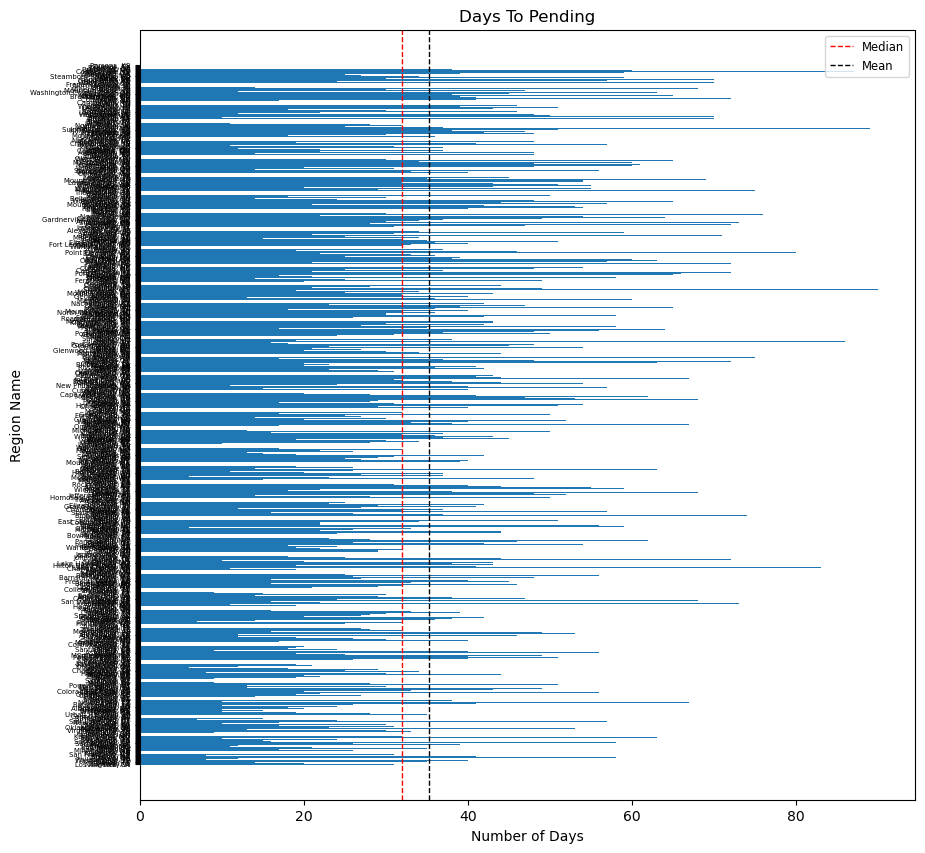

In [276]:
plt.figure(figsize=(10,10))
plt.tick_params(axis='y', labelsize=5)
plt.barh(days_to_pending.index, days_to_pending['2025-03-31'] )
plt.title("Days To Pending")
plt.xlabel("Number of Days")
plt.ylabel("Region Name")
plt.axvline(x=days_median, color='r', linestyle='--', linewidth=1, label="Median")
plt.axvline(x=days_mean, color='black', linestyle='--', linewidth=1, label="Mean")
plt.legend(loc='upper right', fontsize='small')

### This graph shows the days to pending of each state as of the most recent time point. This average was calculated earlier. We chose to use average over median as we felt that in-state outliers were significant enough to include in the by-state analysis. The median and mean are displayed on the graph as well. NC, CO, and TX can all be seen on this chanrt. While they are all at or above the median, the average days are still all within 60 days. To us, that feels like a reasonable amount of time for real estate to be on market and thus not something to worry about

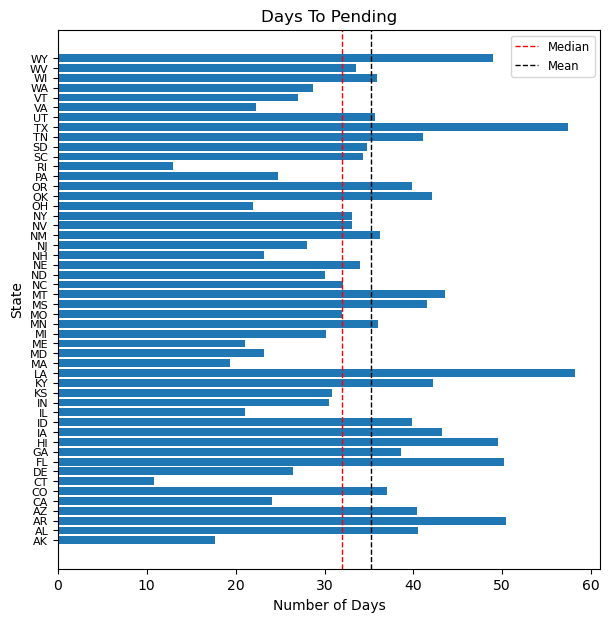

In [277]:
plt.figure(figsize=(7,7))
plt.tick_params(axis='y', labelsize=8)
plt.barh(days_pend_group.index, days_pend_group)
plt.title("Days To Pending")
plt.xlabel("Number of Days")
plt.ylabel("State")
plt.axvline(x=days_median, color='r', linestyle='--', linewidth=1, label="Median")
plt.axvline(x=days_mean, color='black', linestyle='--', linewidth=1, label="Mean")
plt.legend(loc='upper right', fontsize='small')

### This histogram shows the breakdown of all datapoints from the most recent timepoint. It can clearly be seen how the data is right skewed, which is also visable with the mean being to the right of the median. However, most values do lie around the median of 32 days

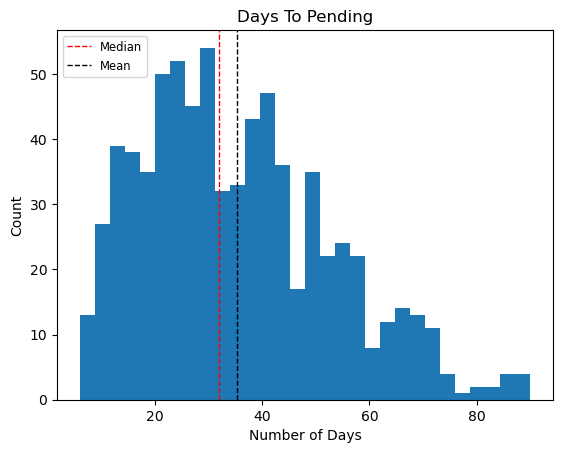

In [278]:
plt.hist(days_to_pending["2025-03-31"], bins = 30)
plt.title("Days To Pending")
plt.xlabel("Number of Days")
plt.ylabel("Count")
plt.axvline(x=days_median, color='r', linestyle='--', linewidth=1, label="Median")
plt.axvline(x=days_mean, color='black', linestyle='--', linewidth=1, label="Mean")
plt.legend(loc='upper left', fontsize='small')

### The next step in our analysis was to evaluate if the days to pending in different region are increasing or decreasing. To do this we subtracted data from one year prior to the most recent timepoint data from the most recent data

In [279]:
one_year_change = days_to_pending["2025-03-31"] - days_to_pending["2024-03-31"]
one_year_change.describe()

count    570.000000
mean       7.896491
std       10.068910
min      -25.000000
25%        2.000000
50%        7.000000
75%       12.000000
max       64.000000
dtype: float64

### Interesting note here: Pandas median calcuation will skip NaN values by default, but the NumPy median calculation will include them and thus the nanmedian methed must be used instead

In [280]:
change_median = np.nanmedian(one_year_change)
change_mean = np.mean(one_year_change)

### The histogram of change in days to pending in the last year clearly shows that the majority of regions have seen an increase in the number of days that real-estate was on the market. Many places had just a small increase of a few days, but a fair amount had significant increases and only a few had significant decreases. Any values that had a null value for the older timepoint were automatically dropped from the dataset

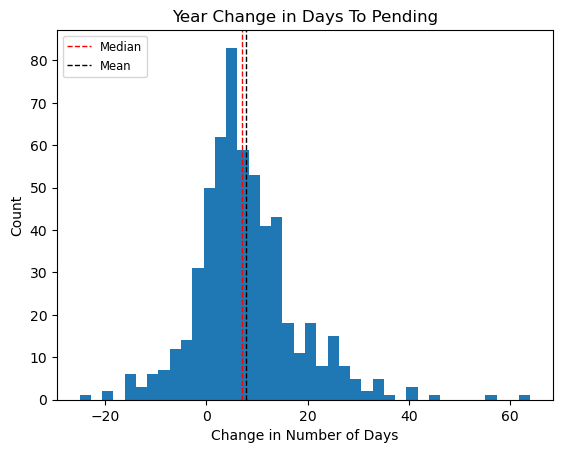

In [281]:
plt.hist(one_year_change, bins = 40)
plt.title("Year Change in Days To Pending")
plt.xlabel("Change in Number of Days")
plt.ylabel("Count")
plt.axvline(x=change_median, color='r', linestyle='--', linewidth=1, label="Median")
plt.axvline(x=change_mean, color='black', linestyle='--', linewidth=1, label="Mean")
plt.legend(loc='upper left', fontsize='small')

### The boxplot below show the Days to Pending data across three timepoints: the most recent, a year prior, and five years prior. We can see that overall, things have not changed too much over the last five years. There are now fewer outliers and the data is more bunched together, but less than it was a year ago. The median from the most recent timepoint and from five years prior are very similar. The one year prior median is just slightly less than the most recent one

In [282]:
dropped2024 = days_to_pending["2024-03-31"].dropna()
dropped2020 = days_to_pending["2020-03-31"].dropna()

Text(0, 0.5, 'Number of Days')

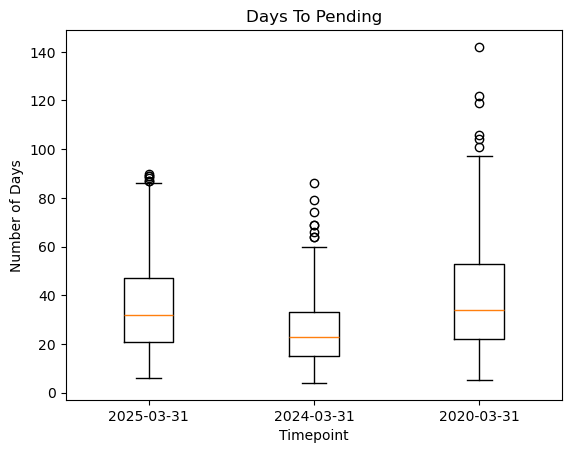

In [283]:
d = [days_to_pending["2025-03-31"],dropped2024, dropped2020]
plt.boxplot(d, labels=["2025-03-31","2024-03-31","2020-03-31"])
plt.title("Days To Pending")
plt.xlabel("Timepoint")
plt.ylabel("Number of Days")

### Overall, we can say that the average days to pending for real estate on the market is about 35 days. There are a handful of regions that with signifcantly higher averages, but for the most part many places are right around these values. The market has also held steady on these values for the last five years or so, so it seems that about 35 days to pending is a typical and stable timeframe. NC, CO, and TX are all at or above these values, but we do not think any of them are concering enough to make them non-viable regions for investments

## 5) How much average profit I could expect from my investments in terms of sale (% dollars) after paying mortgage. Calculate my ~ROI.

# TEMPORARY SECTION
ROI = Net Profit / Total Investment Cost
Net profit being Cost of Sale - Cost of Purchase
I don't believe that we need to make this too complicated, it should just be sale cost minus mortgage payment over mortgage payment (unless we decide on some arbitary investment amount per flip)

We calculate the ROI specifically by finding the median home value for a region, the median sale price for it, the mortgage payment, and ???

First we build the dataframes we will be using to answer the question

In [284]:
saleprice_df = pd.read_csv(salesPrice)
Days_on_Market_df = pd.read_csv(marketDays)
market_growth = pd.read_csv(homeValuesForecast)
mortgage_df = pd.read_csv(mortgagePayment)

Then we transform the dataset

In [285]:
# transform dataset
saleprice_df_transformed = (saleprice_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='SalePrice') # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .sort_values(by=['Date'], ascending=True)
 .reset_index()
 .drop(columns=['index', 'SizeRank', 'RegionID', 'RegionType'])
 # .assign(zscore = lambda df: sp.zscore(df.SalePrice)).round(3)
 .query("Date >= '2022-3-31'") # limit dataset to last 3 years
 .query("StateName == 'NC' or StateName == 'CO'")
 # .assign(Month_Year = lambda df: (df.Date
 #                             .dt.strftime('%b-%Y')
 #                            )
 #        )
 .groupby(['StateName', 'RegionName'])
 .agg({'SalePrice': 'mean'}) # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['SalePrice'], ascending=False)
 .reset_index()
)
saleprice_df_transformed



,StateName,RegionName,SalePrice
0,CO,"Breckenridge, CO",955260.432432
1,CO,"Boulder, CO",725896.486486
2,NC,"Kill Devil Hills, NC",576464.351351
3,CO,"Denver, CO",573003.459459
4,CO,"Fort Collins, CO",541086.729730
5,CO,"Greeley, CO",476568.540541
6,CO,"Colorado Springs, CO",443743.216216
7,NC,"Morehead City, NC",427623.162162
8,NC,"Raleigh, NC",415129.324324
9,NC,"Pinehurst, NC",412200.324324


And visualize it

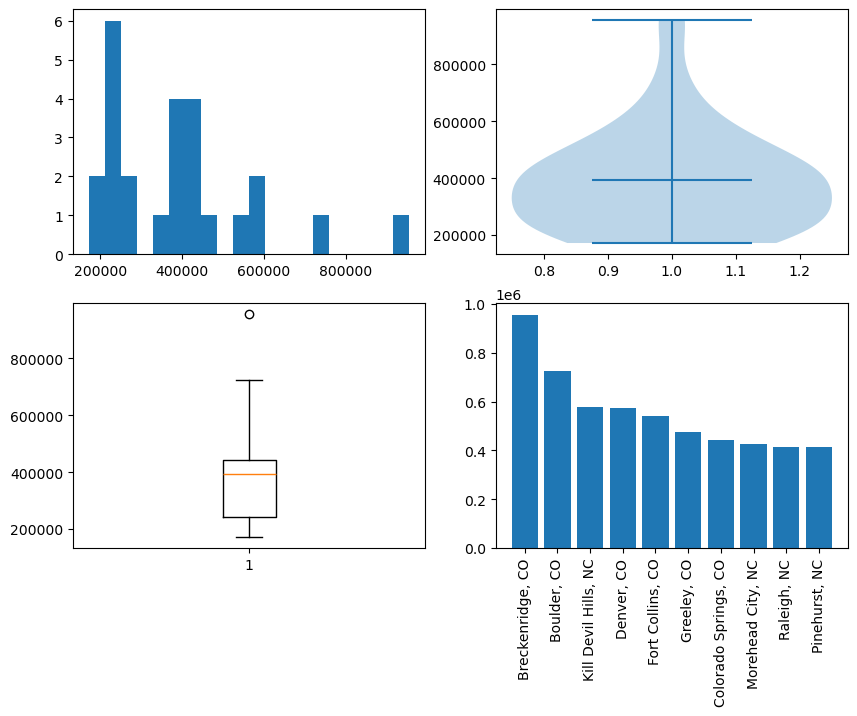

In [286]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.SalePrice, bins=20)
    ax[0,1].violinplot(df.SalePrice, showmedians=True)
    ax[1,0].boxplot(df.SalePrice)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.SalePrice.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(saleprice_df_transformed
 .pipe(graph)
)

Transform the next dataset

In [287]:
Days_on_Market_df_transformed = (Days_on_Market_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='Days_on_Market') # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .sort_values(by=['Date'], ascending=True)
 .reset_index()
 .drop(columns=['index', 'SizeRank', 'RegionID', 'RegionType'])
 # .assign(zscore = lambda df: sp.zscore(df.SalePrice)).round(3)
 .query("Date >= '2022-3-31'") # limit dataset to last 3 years
 .query("StateName == 'NC' or StateName == 'CO'")
 # .assign(Month_Year = lambda df: (df.Date
 #                             .dt.strftime('%b-%Y')
 #                            )
 #        )
 .groupby(['StateName', 'RegionName'])
 .agg({'Days_on_Market': 'mean'}).div(30).round(2) # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['Days_on_Market'], ascending=False)
 .rename(columns={'Days_on_Market': 'Months_on_Market'})
 .reset_index()
)
Days_on_Market_df_transformed

,StateName,RegionName,Months_on_Market
0,CO,"Ca-¦on City, CO",2.42
1,NC,"Cullowhee, NC",1.77
2,CO,"Sterling, CO",1.77
3,NC,"Washington, NC",1.56
4,NC,"Laurinburg, NC",1.43
5,NC,"Roanoke Rapids, NC",1.42
6,CO,"Montrose, CO",1.36
7,NC,"Henderson, NC",1.33
8,NC,"Shelby, NC",1.25
9,NC,"Lumberton, NC",1.13


And the next

In [288]:
market_growth_transformed = (market_growth
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .drop(columns=['BaseDate', '2025-04-30', '2025-06-30']) # Keep only 1 year market growth forecast
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='MarketGrowth')  # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .reset_index()
 .query("StateName == 'NC' or StateName == 'CO'")
 .drop(columns=['index', 'RegionID', 'SizeRank', 'RegionType', 'Date'])
 .set_index('StateName')
 .sort_values(by=['MarketGrowth'], ascending=False)
 .reset_index()
 .assign(Market_Growth = lambda df: df.MarketGrowth * .01)
 .drop(columns=['MarketGrowth'])
 .rename(columns={'Market_Growth': 'MarketGrowth'})
)
market_growth_transformed

,StateName,RegionName,MarketGrowth
0,CO,"Steamboat Springs, CO",0.038
1,CO,"Edwards, CO",0.027
2,NC,"Brevard, NC",0.018
3,CO,"Glenwood Springs, CO",0.016
4,NC,"Boone, NC",0.013
5,NC,"Kinston, NC",0.013
6,NC,"Albemarle, NC",0.013
7,NC,"Sanford, NC",0.013
8,NC,"Pinehurst, NC",0.010
9,NC,"Wilson, NC",0.009


And the last

In [289]:
print(sale_count_df_transformed.columns)
print(Days_on_Market_df_transformed.columns)
print(market_growth_transformed.columns)
print(saleprice_df_transformed.columns)

Index(['StateName', 'RegionName', 'SaleCount', 'zscore'], dtype='object')
Index(['StateName', 'RegionName', 'Months_on_Market'], dtype='object')
Index(['StateName', 'RegionName', 'MarketGrowth'], dtype='object')
Index(['StateName', 'RegionName', 'SalePrice'], dtype='object')


In [290]:
mortgage_df_transformed = (mortgage_df
 .dropna(subset=['StateName'])  # drop null value from StateName column (that is null because it is evaluating the entire US
 .melt(['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'], var_name='Date', value_name='MortgagePayment') # reshape dataset
 .astype({'Date': 'datetime64[ns]'})
 .sort_values(by=['Date'], ascending=True)
 .reset_index()
 .drop(columns=['index', 'SizeRank', 'RegionID', 'RegionType'])
 # .assign(zscore = lambda df: sp.zscore(df.SalePrice)).round(3)
 .query("Date >= '2022-3-31'") # limit dataset to last 3 years
 .query("StateName == 'NC' or StateName == 'CO'")
 # .assign(Month_Year = lambda df: (df.Date
 #                             .dt.strftime('%b-%Y')
 #                            )
 #        )
 .groupby(['StateName', 'RegionName'])
 .agg({'MortgagePayment': 'mean'}).round(2) # take mean of last 3 years for each StateName and RegionName
 .sort_values(by=['MortgagePayment'], ascending=False)
 .reset_index()
 .merge(saleprice_df_transformed, how='left', on=['StateName', 'RegionName'])
 .rename(columns={'SalePrice': 'BuyPrice'})
 .merge(Days_on_Market_df_transformed, how='left', on=['StateName', 'RegionName'])
 .merge(market_growth_transformed, how='left', on=['StateName', 'RegionName'])
 .assign(Months_Renovating = 6)
 .assign(TotalMortgageCost = lambda df: (df.MortgagePayment * (df.Months_on_Market + df.Months_Renovating)))                    
 .assign(Cost_of_Rennovation = 50000)
 .assign(TotalCost = lambda df: (df.BuyPrice + df.TotalMortgageCost + df.Cost_of_Rennovation))
 .assign(GrossProfit = lambda df: ((df.BuyPrice + (df.BuyPrice * df.MarketGrowth))) + (df.Cost_of_Rennovation * 2))
 .assign(NetProfit = lambda df: df.GrossProfit - df.TotalCost)
 .sort_values('NetProfit', ascending=False)
 .dropna()
)
mortgage_df_transformed

,StateName,RegionName,MortgagePayment,BuyPrice,Months_on_Market,MarketGrowth,Months_Renovating,TotalMortgageCost,Cost_of_Rennovation,TotalCost,GrossProfit,NetProfit
20,NC,"Fayetteville, NC",1159.56,227108.729730,0.35,0.007,6,7363.2060,50000,284471.935730,328698.490838,44226.555108
19,NC,"Greenville, NC",1159.88,223614.891892,0.35,0.005,6,7365.2380,50000,280980.129892,324732.966351,43752.836459
21,NC,"Rocky Mount, NC",949.47,172005.837838,0.60,0.000,6,6266.5020,50000,228272.339838,272005.837838,43733.498000
18,NC,"New Bern, NC",1193.45,260603.243243,0.43,0.003,6,7673.8835,50000,318277.126743,361385.052973,43107.926230
17,NC,"Hickory, NC",1210.74,236232.432432,0.67,-0.002,6,8075.6358,50000,294308.068232,335759.967568,41451.899335
10,NC,"Pinehurst, NC",1966.80,412200.324324,0.52,0.010,6,12823.5360,50000,475023.860324,516322.327568,41298.467243
14,NC,"Jacksonville, NC",1327.67,250299.972973,0.36,-0.003,6,8443.9812,50000,308743.954173,349549.073054,40805.118881
16,NC,"Greensboro, NC",1228.10,231258.189189,0.38,-0.010,6,7835.2780,50000,289093.467189,328945.607297,39852.140108
15,NC,"Winston, NC",1281.44,241567.729730,0.37,-0.011,6,8162.7728,50000,299730.502530,338910.484703,39179.982173
22,NC,"Goldsboro, NC",861.69,206854.243243,0.46,-0.029,6,5566.5174,50000,262420.760643,300855.470189,38434.709546


In [291]:
mortgage_df_transformed["ROI"] = (mortgage_df_transformed["NetProfit"] / mortgage_df_transformed["TotalCost"]) * 100
print(mortgage_df_transformed[["RegionName", "TotalCost", "NetProfit", "ROI"]].sort_values(by="ROI", ascending=False))


              RegionName      TotalCost     NetProfit        ROI
21       Rocky Mount, NC  228272.339838  43733.498000  19.158474
19        Greenville, NC  280980.129892  43752.836459  15.571506
20      Fayetteville, NC  284471.935730  44226.555108  15.546896
22         Goldsboro, NC  262420.760643  38434.709546  14.646215
17           Hickory, NC  294308.068232  41451.899335  14.084527
16        Greensboro, NC  289093.467189  39852.140108  13.785210
18          New Bern, NC  318277.126743  43107.926230  13.544148
14      Jacksonville, NC  308743.954173  40805.118881  13.216492
15           Winston, NC  299730.502530  39179.982173  13.071737
12            Pueblo, CO  337242.739351  32588.853216   9.663322
10         Pinehurst, NC  475023.860324  41298.467243   8.693977
11         Charlotte, NC  424021.571173  36619.223881   8.636170
6         Wilmington, NC  462468.554459  37594.504378   8.129094
9     Grand Junction, CO  436988.754435  33403.575484   7.644035
8             Durham, NC 

Graphs for calculated ROI

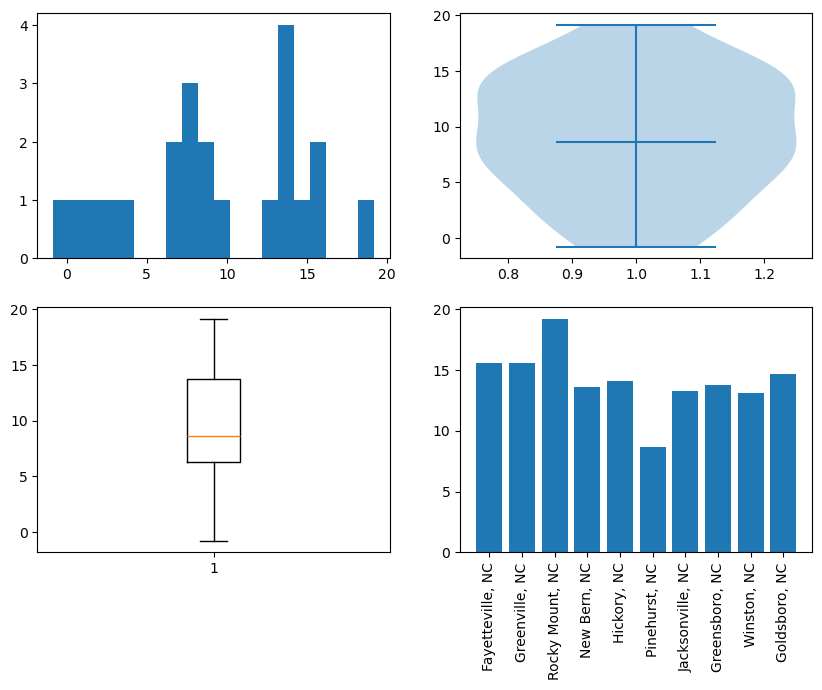

In [292]:
fig, ax = plt.subplots(2,2,figsize=(10,7))
def graph(df):
    ax[0,0].hist(df.ROI, bins=20)
    ax[0,1].violinplot(df.ROI, showmedians=True)
    ax[1,0].boxplot(df.ROI)
    ax[1,1].bar(x=df.RegionName.head(10), height=df.ROI.head(10))
    ax[1,1].tick_params(axis='x', labelrotation=90)
    return plt.show()

(mortgage_df_transformed
 .pipe(graph)
)

If you were to buy 1 house in each region (for diversity sake), you would not exceed the $12 million dollar budget and would in fact come in quite a bit below. That means you can spend more on refurbishing or buy multiple properties from a single city.

In [293]:
# Sort by ROI in descending order & filter for positive ROI values
mortgage_df_filtered = mortgage_df_transformed[mortgage_df_transformed["ROI"] > 0].sort_values(by="ROI", ascending=False)

# Initialize variables
selected_properties = []
total_cost = 0
budget_limit = 12_000_000  # 12 million dollars

# Loop through properties and add them until total cost reaches the limit
for _, row in mortgage_df_filtered.iterrows():
    if total_cost + row["TotalCost"] <= budget_limit:
        selected_properties.append(row)
        total_cost += row["TotalCost"]
    else:
        break  # Stop adding properties once we hit the budget limit

# Convert selected properties to a new DataFrame
selected_df = pd.DataFrame(selected_properties)

# Print the selected properties
print(selected_df[["RegionName", "TotalCost", "NetProfit", "ROI"]])

# Print total cost to verify it stays under 12 million
print(f"Total investment cost: ${total_cost:,.2f}")


              RegionName      TotalCost     NetProfit        ROI
21       Rocky Mount, NC  228272.339838  43733.498000  19.158474
19        Greenville, NC  280980.129892  43752.836459  15.571506
20      Fayetteville, NC  284471.935730  44226.555108  15.546896
22         Goldsboro, NC  262420.760643  38434.709546  14.646215
17           Hickory, NC  294308.068232  41451.899335  14.084527
16        Greensboro, NC  289093.467189  39852.140108  13.785210
18          New Bern, NC  318277.126743  43107.926230  13.544148
14      Jacksonville, NC  308743.954173  40805.118881  13.216492
15           Winston, NC  299730.502530  39179.982173  13.071737
12            Pueblo, CO  337242.739351  32588.853216   9.663322
10         Pinehurst, NC  475023.860324  41298.467243   8.693977
11         Charlotte, NC  424021.571173  36619.223881   8.636170
6         Wilmington, NC  462468.554459  37594.504378   8.129094
9     Grand Junction, CO  436988.754435  33403.575484   7.644035
8             Durham, NC 

## 6) How much average monthly income I could expect from my investments in terms of lease/rent after upgrading properties, paying mortgage, and paying taxes. Calculate my ~ROI.

In [11]:
final_analysis = (monthly_payment_df_transformed
                  .merge(rent_df_transformed, how='left', on=['StateName', 'RegionName'])
                  .assign(difference = lambda df: df.RentalPrice - df.MonthlyPayment)
                  .sort_values('difference', ascending=False)
                  .assign(Rennovation_Cost = 50000)
                 )
final_analysis
 
# Net Profit / Total cost * 100
# Net Profit is difference
# Total Cost divided by 120
RentROI = (lambda df: df.RentalPrice - df.MonthlyPayment) / ((lambda df: (df.BuyPrice + df.TotalMortgageCost + df.Cost_of_Rennovation))/120)
print(RentROI)
 

NameError: name 'monthly_payment_df_transformed' is not defined

# Summary

The Zillow data sets provided many options for developing a real estate investment strategy.  After exploring the various data sets and discussing how to have coordinated data sets that would provide a complete analysis of the prompts, we took a funnel approach: after a quick look at national numbers, we analyzed aggregated state data, specifically looking for states with the highest number of regions with leading indicators, i.e. those states who had the most regions at 75% percentile or above in these categories:  high growth, high rental rates, stable/moderate inventory, and buyer vs. seller market. The states on top of lists for each of these indicators were North Carolina and Colorado.
After confirming that the sales prices are forecasted to go up in both states– endorsing a “buy now” strategy - and the inventory would remain fairly static, we then drilled into analysis by region.
For both forecasting and days-to-analysis data, we focused on regions within North Carolina and Colorado. Successful investment will depend on choosing specific regions in each state, as the data indicates that not all regions in each state have positive forecasts.
To validate that a sell strategy would not succumb to a slow market, i.e. many days on the market, we analyzed the days to pending sale and confirmed that North Carolina and Colorado were at or comfortably in range with the median.
Summary of prompts 5, 6 and final recommendation. 